# LAB 10 : Impact of PCA on K-Means Clustering

Task 1: Data Preparation

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

# Load dataset and split into feature matrix and ground-truth labels
digits_bundle = load_digits()
pixel_features = digits_bundle.data
true_digits = digits_bundle.target

print(f"Feature matrix shape: {pixel_features.shape}")
print(f"Target classes: {np.unique(true_digits)}")

Feature matrix shape: (1797, 64)
Target classes: [0 1 2 3 4 5 6 7 8 9]


In [2]:
scaler_obj = StandardScaler()
scaled_pixels = scaler_obj.fit_transform(pixel_features)

print(f"Overall mean after scaling: {scaled_pixels.mean():.4f}")
print(f"Overall std dev after scaling: {scaled_pixels.std():.4f}")

Overall mean after scaling: 0.0000
Overall std dev after scaling: 0.9763


Task 2: Baseline K-Means Clustering (Before PCA)

In [3]:
def run_timed_kmeans(data_matrix, seed=42):
    cluster_model = KMeans(
        n_clusters=10,
        init="k-means++",
        n_init=10,
        random_state=seed
    )
    t_start = time.perf_counter()
    assigned_labels = cluster_model.fit_predict(data_matrix)
    duration_sec = time.perf_counter() - t_start
    return cluster_model, assigned_labels, duration_sec

raw_kmeans, raw_clusters, time_before_pca = run_timed_kmeans(scaled_pixels)
print(f"Baseline 64D K-Means execution time: {time_before_pca:.4f} seconds")

Baseline 64D K-Means execution time: 0.3060 seconds


Task 3: Dimensionality Reduction Using PCA

In [4]:
pca_reducer = PCA(n_components=0.95, random_state=42)
reduced_pixels = pca_reducer.fit_transform(scaled_pixels)

retained_dims = pca_reducer.n_components_

# Project compressed features back to 64D scaled space, then unscale to original pixel range
reconstructed_scaled = pca_reducer.inverse_transform(reduced_pixels)
reconstructed_digits = scaler_obj.inverse_transform(reconstructed_scaled)

print(f"Original dimensions: {scaled_pixels.shape[1]}")
print(f"Components retained for 95% variance: {retained_dims}")
print(f"Reconstructed matrix shape: {reconstructed_digits.shape}")

Original dimensions: 64
Components retained for 95% variance: 40
Reconstructed matrix shape: (1797, 64)


Task 4: Reduced-Dimensional K-Means Clustering (After PCA)

In [5]:
pca_kmeans, pca_clusters, time_after_pca = run_timed_kmeans(reduced_pixels)
print(f"PCA-reduced ({retained_dims}D) K-Means execution time: {time_after_pca:.4f} seconds")

PCA-reduced (40D) K-Means execution time: 0.1661 seconds


Task 5: Comparative Analysis and Visualization

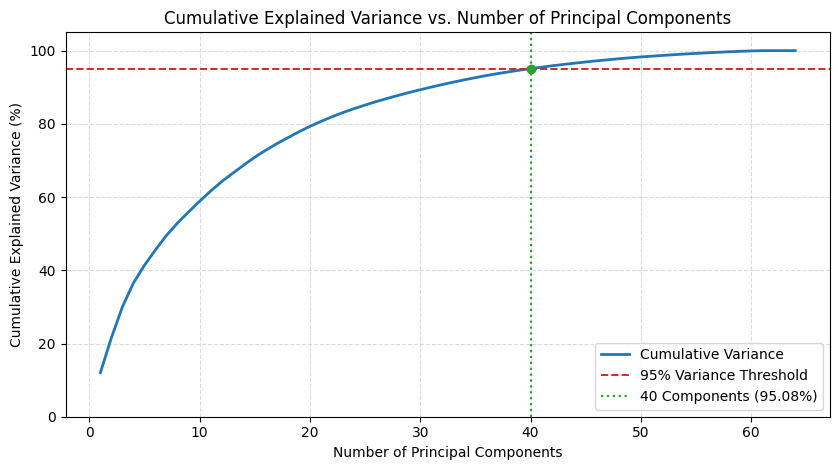

In [6]:
full_pca = PCA().fit(scaled_pixels)
cum_variance = np.cumsum(full_pca.explained_variance_ratio_) * 100
component_axis = np.arange(1, len(cum_variance) + 1)

fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.plot(component_axis, cum_variance, color="#1f77b4", linewidth=2, label="Cumulative Variance")
ax.axhline(y=95, color="#d62728", linestyle="--", linewidth=1.4, label="95% Variance Threshold")
ax.axvline(
    x=retained_dims,
    color="#2ca02c",
    linestyle=":",
    linewidth=1.6,
    label=f"{retained_dims} Components ({cum_variance[retained_dims - 1]:.2f}%)"
)
ax.scatter([retained_dims], [cum_variance[retained_dims - 1]], color="#2ca02c", zorder=5)

ax.set_title("Cumulative Explained Variance vs. Number of Principal Components")
ax.set_xlabel("Number of Principal Components")
ax.set_ylabel("Cumulative Explained Variance (%)")
ax.set_ylim(0, 105)
ax.grid(True, linestyle="--", alpha=0.45)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

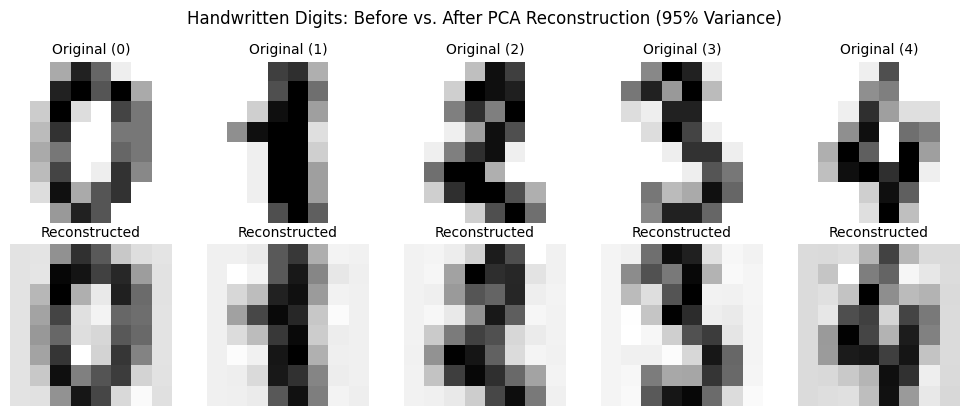

In [7]:
sample_indices = [0, 1, 2, 3, 4]  # First 5 images (digits 0 to 4)
num_samples = len(sample_indices)

fig, axes = plt.subplots(2, num_samples, figsize=(10, 4.2))
for col, idx in enumerate(sample_indices):
    # Top row: Original image
    axes[0, col].imshow(pixel_features[idx].reshape(8, 8), cmap="binary")
    axes[0, col].set_title(f"Original ({true_digits[idx]})", fontsize=10)
    axes[0, col].axis("off")

    # Bottom row: PCA reconstructed image
    axes[1, col].imshow(reconstructed_digits[idx].reshape(8, 8), cmap="binary")
    axes[1, col].set_title("Reconstructed", fontsize=10)
    axes[1, col].axis("off")

fig.suptitle("Handwritten Digits: Before vs. After PCA Reconstruction (95% Variance)", fontsize=12)
plt.tight_layout()
plt.show()

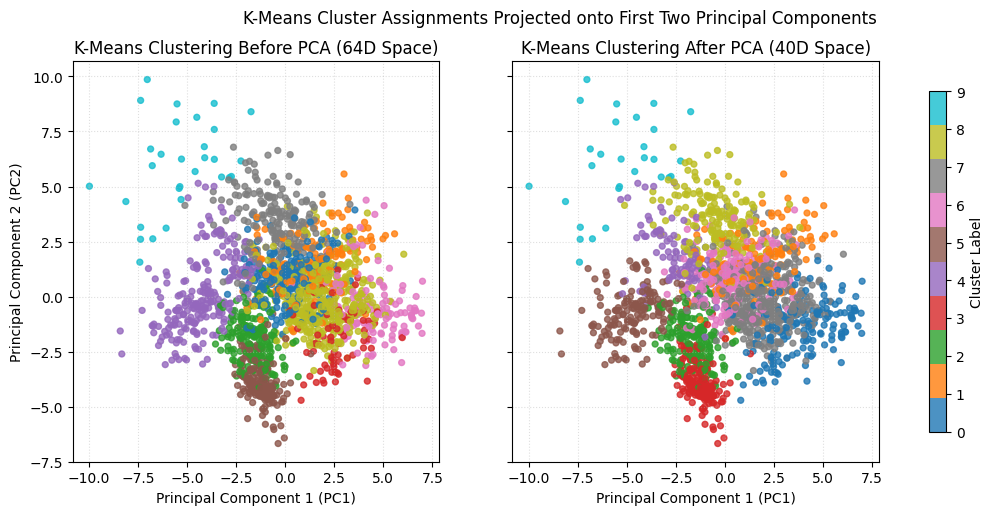

In [8]:
pc1 = reduced_pixels[:, 0]
pc2 = reduced_pixels[:, 1]

fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(13, 5.2), sharex=True, sharey=True)

scatter_before = ax_left.scatter(pc1, pc2, c=raw_clusters, cmap="tab10", s=18, alpha=0.8)
ax_left.set_title("K-Means Clustering Before PCA (64D Space)")
ax_left.set_xlabel("Principal Component 1 (PC1)")
ax_left.set_ylabel("Principal Component 2 (PC2)")
ax_left.grid(True, linestyle=":", alpha=0.4)

scatter_after = ax_right.scatter(pc1, pc2, c=pca_clusters, cmap="tab10", s=18, alpha=0.8)
ax_right.set_title(f"K-Means Clustering After PCA ({retained_dims}D Space)")
ax_right.set_xlabel("Principal Component 1 (PC1)")
ax_right.grid(True, linestyle=":", alpha=0.4)

fig.colorbar(scatter_after, ax=[ax_left, ax_right], label="Cluster Label", shrink=0.85)
fig.suptitle("K-Means Cluster Assignments Projected onto First Two Principal Components", fontsize=12)
plt.show()

In [9]:
summary_df = pd.DataFrame({
    "Evaluation Metric": [
        "Number of Features",
        "Execution Time (seconds)"
    ],
    "Before PCA": [
        scaled_pixels.shape[1],
        round(time_before_pca, 4)
    ],
    "After PCA": [
        retained_dims,
        round(time_after_pca, 4)
    ]
})

print(summary_df.to_string(index=False))

       Evaluation Metric  Before PCA  After PCA
      Number of Features      64.000    40.0000
Execution Time (seconds)       0.306     0.1661
